In [ ]:
# --- project root (added when the folder was organised): run notebooks from the project folder
import os, sys
from pathlib import Path
_p = Path.cwd()
while not (_p / "preprocess.py").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p); sys.path.insert(0, str(_p))
print("working folder:", _p)

# 07 — Step 4: year-context input channels (round 4)

**Change tested:** the model sees the month **plus 4 extra channels describing the whole year** at each pixel:
12-month **mean** and **standard deviation** of VV and VH (7 input channels instead of 3).

**Why:** a single month is ambiguous (a harvested field in December looks like bare soil or grass). The yearly
mean/std tells the model how the pixel *behaves over the year*: crops change a lot (high std), trees, water and
cities are stable (low std). Expected gains: Cropland vs Grass vs Trees, and a smaller winter dip
(less fake "change" in the prototype). Everything is still **Sentinel-1 only**.

| Run | = settings of | + change |
|---|---|---|
| `A_unet_v4` | `A_unet_v2` (60 epochs, Lovász) | `FEATURES = "monthly+year"` |
| `C_segformer_v4` | `C_segformer_v3` (LR 6e-5, regularised) | `FEATURES = "monthly+year"` |

No new preprocessing: the year channels are computed from the 12 months already stored in each `data_r3` patch
(`train_lib_r4.py`). Their normalisation statistics are computed once from the training patches and saved as
`data_r3/norm_stats_year.json` (a new file; nothing existing is changed).
Compare afterwards with **05c_compare_r4.ipynb**.

* Finished experiments are **skipped** on re-run, unfinished ones **resume**.

## 1. Setup

In [7]:
import importlib, subprocess, sys
if importlib.util.find_spec("segmentation_models_pytorch") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--user", "-q",
                           "--no-warn-script-location", "segmentation-models-pytorch"])
sys.path.append(".")
import gc, json, torch
from pathlib import Path
import train_lib_r4 as tl
from train_lib_r4 import DEV
print("torch", torch.__version__, "| device:", DEV)

torch 2.9.1+cu128 | device: cuda


## 2. Experiment list

`BASE` = the settings used in 04a/b/c. Each experiment only lists what it changes (v4 = v2/v3 settings + year channels).
Comment out (`#`) any line you don't want to run now.

In [8]:
BASE = dict(
    DATA="data_r3", PRETRAINED=True, EPOCHS=40, WARMUP_EPOCHS=2, BATCH_SIZE=16, LR=3e-4,
    WEIGHT_DECAY=1e-4, PATIENCE=8, USE_CLASS_WEIGHTS=True, LOSS="dice", LABEL_SMOOTHING=0.0,
    NOISE_DB=1.0, MONTH_MIX=0.0, NUM_WORKERS=0, SEED=42, FEATURES="monthly",
)
LONGER_LOVASZ = dict(EPOCHS=60, PATIENCE=12, LOSS="lovasz")

YEAR = dict(FEATURES="monthly+year")

EXPERIMENTS = [
    # ---- step 4: best two models from round 3 + year-context channels
    dict(RUN_NAME="A_unet_v4",      GROUP="A_unet_v4",      ARCH="unet_resnet34",
         MODEL_NAME="U-Net / ResNet-34 v4 (+year)",  **LONGER_LOVASZ, **YEAR),
    dict(RUN_NAME="C_segformer_v4", GROUP="C_segformer_v4", ARCH="segformer_mitb2",
         MODEL_NAME="SegFormer / MiT-B2 v4 (+year)", **LONGER_LOVASZ, LR=6e-5, WARMUP_EPOCHS=5,
         WEIGHT_DECAY=0.01, NOISE_DB=2.0, MONTH_MIX=0.3, **YEAR),
]
for e in EXPERIMENTS:
    print(f"{e['RUN_NAME']:18s} {e['ARCH']:24s} " + ", ".join(f"{k}={v}" for k, v in e.items()
          if k not in ("RUN_NAME", "GROUP", "ARCH", "MODEL_NAME") and BASE.get(k) != v))

A_unet_v4          unet_resnet34            EPOCHS=60, PATIENCE=12, LOSS=lovasz, FEATURES=monthly+year
C_segformer_v4     segformer_mitb2          EPOCHS=60, PATIENCE=12, LOSS=lovasz, LR=6e-05, WARMUP_EPOCHS=5, WEIGHT_DECAY=0.01, NOISE_DB=2.0, MONTH_MIX=0.3, FEATURES=monthly+year


## 3. Year-channel statistics and validation set (loaded once)
The first run computes `data_r3/norm_stats_year.json` from the training patches (a few minutes); later runs reuse it.

In [9]:
import shutil
_tmp, DATA, stats, index = tl.setup(dict(BASE, RUN_NAME="_tmp")); shutil.rmtree(_tmp)
ystats = tl.year_stats(index, DATA)
print("year channels:", dict(zip(ystats["names"], zip(ystats["mean"], ystats["std"]))))
val_ds = tl.EvalPatches(index[index.split == "val"].file, DATA, stats, "loading val", ystats=ystats)
print("val regions:", sorted(index[index.split == "val"].region.unique()))
print("train patches:", (index.split == "train").sum(), "| val patches:", (index.split == "val").sum())

device: cuda | GPU: NVIDIA RTX A6000, 50.9 GB
year channels: {'VV_mean': (-10.7849, 5.2237), 'VH_mean': (-18.5519, 5.5824), 'VV_std': (1.4127, 0.706), 'VH_std': (1.5016, 0.8163)}


loading val:   0%|          | 0/128 [00:00<?, ?it/s]

val regions: ['bangkok', 'danube_delta', 'iowa', 'las_vegas', 'madrid', 'saskatchewan', 'serengeti', 'sudd_wetland']
train patches: 700 | val patches: 128


## 4. Run all experiments
For each experiment: setup → data → model → sanity check → training → curves → validation results.


A_unet_v4  —  U-Net / ResNet-34 v4 (+year)
device: cuda | GPU: NVIDIA RTX A6000, 50.9 GB
train patches 700 | val samples 1536 (128 patches x 12 months)
24.4 M parameters | encoder weights: imagenet | loss: CE + lovasz | input channels: 7
step  0  loss 3.195
step 10  loss 1.417
step 20  loss 1.004
step 29  loss 0.788


epoch 0:   0%|          | 0/43 [00:00<?, ?it/s]

ep  0 | train 2.240 | val 2.121 | OA 0.622 | mIoU 0.357  *best* | 48s


epoch 1:   0%|          | 0/43 [00:00<?, ?it/s]

ep  1 | train 1.631 | val 2.182 | OA 0.558 | mIoU 0.392  *best* | 47s


epoch 2:   0%|          | 0/43 [00:00<?, ?it/s]

... (51 outputs left out)

epoch 28:   0%|          | 0/43 [00:00<?, ?it/s]

ep 28 | train 0.741 | val 1.458 | OA 0.764 | mIoU 0.566 | 48s


epoch 29:   0%|          | 0/43 [00:00<?, ?it/s]

ep 29 | train 0.721 | val 1.453 | OA 0.765 | mIoU 0.548 | 53s
Early stopping.
Done. Best val mIoU: 0.5682


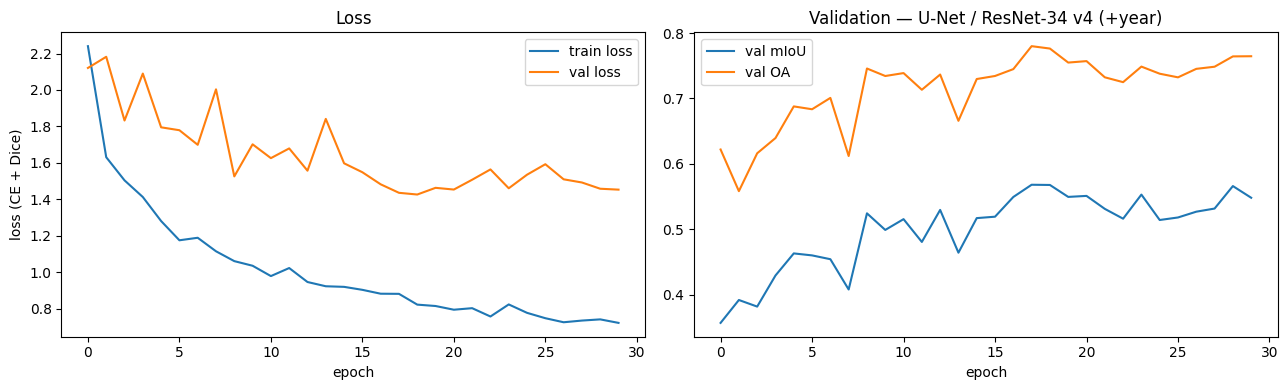

U-Net / ResNet-34 v4 (+year): val OA 0.780 | val mIoU 0.568 | 24.4 M params | 23.8 min


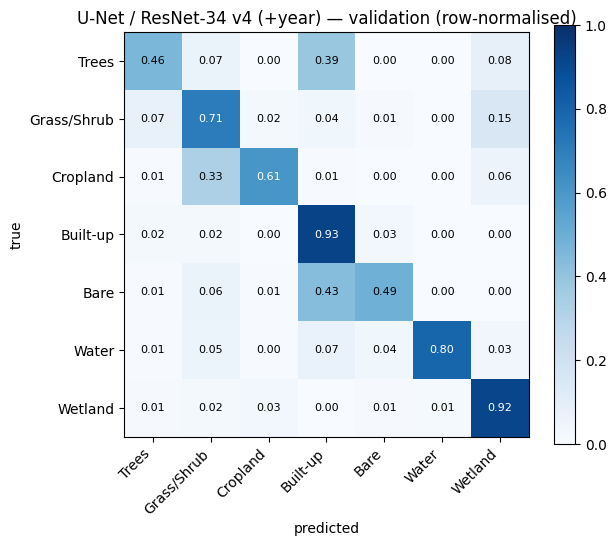

,IoU,F1
Trees,0.373,0.544
Grass/Shrub,0.572,0.728
Cropland,0.537,0.699
Built-up,0.771,0.871
Bare,0.252,0.403
Water,0.730,0.844
Wetland,0.741,0.851
mean,0.568,0.706



C_segformer_v4  —  SegFormer / MiT-B2 v4 (+year)
device: cuda | GPU: NVIDIA RTX A6000, 50.9 GB
train patches 700 | val samples 1536 (128 patches x 12 months)
24.7 M parameters | encoder weights: imagenet | loss: CE + lovasz | input channels: 7
step  0  loss 3.124
step 10  loss 1.027
step 20  loss 0.873
step 29  loss 0.803


epoch 0:   0%|          | 0/43 [00:00<?, ?it/s]

ep  0 | train 2.608 | val 2.412 | OA 0.503 | mIoU 0.247  *best* | 56s


epoch 1:   0%|          | 0/43 [00:00<?, ?it/s]

ep  1 | train 1.599 | val 1.856 | OA 0.671 | mIoU 0.394  *best* | 53s


... (56 outputs left out)

epoch 30:   0%|          | 0/43 [00:00<?, ?it/s]

ep 30 | train 0.565 | val 1.298 | OA 0.798 | mIoU 0.597 | 53s


epoch 31:   0%|          | 0/43 [00:00<?, ?it/s]

ep 31 | train 0.560 | val 1.340 | OA 0.794 | mIoU 0.588 | 53s
Early stopping.
Done. Best val mIoU: 0.6126


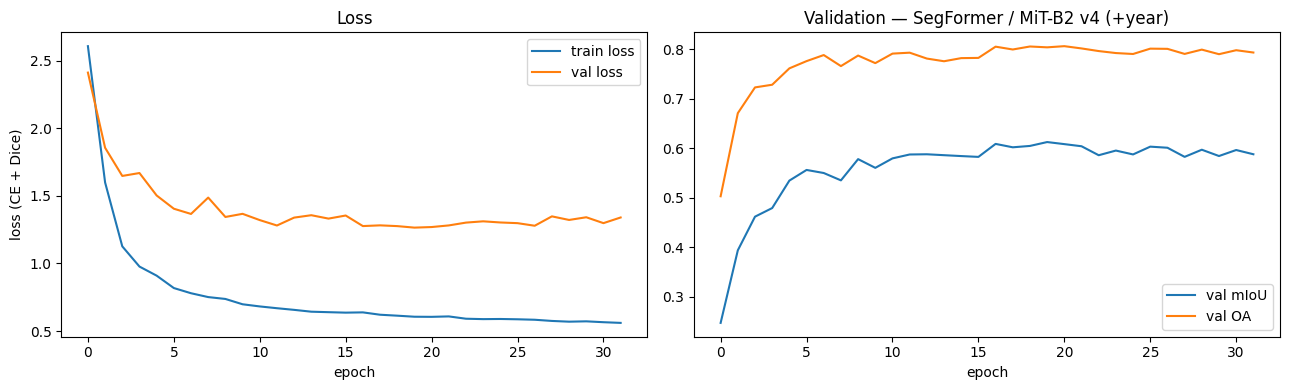

SegFormer / MiT-B2 v4 (+year): val OA 0.804 | val mIoU 0.613 | 24.7 M params | 28.5 min


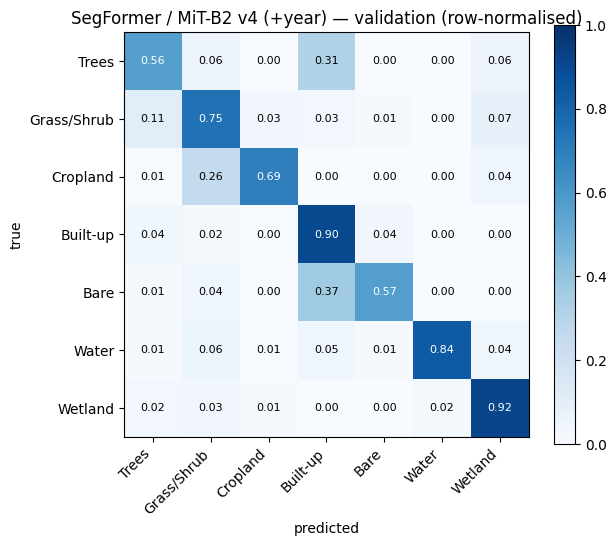

,IoU,F1
Trees,0.409,0.581
Grass/Shrub,0.616,0.762
Cropland,0.622,0.767
Built-up,0.779,0.876
Bare,0.310,0.474
Water,0.746,0.855
Wetland,0.807,0.893
mean,0.613,0.744


In [10]:
summary = []
for exp in EXPERIMENTS:
    CFG = dict(BASE, **exp)
    RUN = Path("runs") / CFG["RUN_NAME"]
    print("\n" + "=" * 90 + f"\n{CFG['RUN_NAME']}  —  {CFG['MODEL_NAME']}\n" + "=" * 90)
    if (RUN / "metrics.json").exists():
        m = json.load(open(RUN / "metrics.json"))
        print(f"already finished -> skipped (val mIoU {m['val_miou']:.3f})")
        summary.append(m); continue

    RUN, DATA, stats, index = tl.setup(CFG)
    train_dl, val_dl = tl.make_loaders(CFG, DATA, stats, index, val_ds=val_ds, ystats=ystats)
    model, CFG["WEIGHTS_USED"] = tl.build_pretrained(CFG["ARCH"], CFG["PRETRAINED"], tl.in_channels_of(CFG))
    json.dump(CFG, open(RUN / "config.json", "w"), indent=2)
    model = model.to(DEV)
    loss_fn = tl.make_loss(CFG, stats)
    print(f"{tl.count_params(model):.1f} M parameters | encoder weights: {CFG['WEIGHTS_USED']} | loss: CE + {CFG['LOSS']} | input channels: {tl.in_channels_of(CFG)}")
    if not (RUN / "last.pth").exists():
        tl.overfit_one_batch(model, loss_fn, train_dl, steps=30, lr=CFG["LR"] * 3)

    tl.train(model, CFG, RUN, train_dl, val_dl, loss_fn)
    tl.plot_curves(RUN, CFG["MODEL_NAME"])
    display(tl.final_validation(model, CFG, RUN, val_dl))
    summary.append(json.load(open(RUN / "metrics.json")))

    del model, train_dl; gc.collect()
    if DEV == "cuda": torch.cuda.empty_cache()

## 5. Summary of this notebook's runs

In [11]:
import pandas as pd
tab = pd.DataFrame([{"run": m["run"], "val OA": m["val_oa"], "val mIoU": m["val_miou"],
                     "best epoch": m["best_epoch"], "epochs": m["epochs_run"], "min": m["train_minutes"]}
                    for m in summary]).set_index("run").sort_values("val mIoU", ascending=False)
display(tab)
print("Now run 05c_compare_r4.ipynb to compare with all earlier runs on the same validation and test sets.")

,val OA,val mIoU,best epoch,epochs,min
run,,,,,
C_segformer_v4,0.8043,0.6126,19,32,28.5
A_unet_v4,0.7799,0.5682,17,30,23.8


Now run 05c_compare_r4.ipynb to compare with all earlier runs on the same validation and test sets.


## 6. Save results

In [ ]:
import shutil
for m in summary:
    shutil.make_archive(f"{m['run']}_results", "zip", Path("runs") / m["run"])
    print("zipped:", f"{m['run']}_results.zip")